# WATERWATCH AI 💧🤖
## Phase 5, 6, 7 & 8: Baseline Benchmark, Model Training, Advanced Evaluation & Handover
**Role:** Member 1 – Data & ML Engineer  
**Project:** Explainable AI-Based Water Potability Prediction and Community Risk Monitoring System  

---

### Objectives & Core Responsibilities
1. **Dataset Loading:** Robust relative path `../data/raw/water_potability.csv` (with fallback to `data/raw/water_potability.csv`).
2. **Dummy Classifier Baseline:** Establish a scientific majority-class benchmark (`strategy='most_frequent'`).
3. **Gaussian Naive Bayes (Phase 5):** Probabilistic parametric classifier with median imputation and standardization.
4. **Decision Tree Classifier (Phase 6):** Non-linear tree partitioner regularized to control variance.
5. **Rigorous Multi-Metric Evaluation & Community Risk Screening (Phase 7):**
   - Precise interpretation of confusion matrix terminology.
   - Explicit reporting of the **dangerous screening error**: *actual non-potable water falsely predicted as potable*.
   - Objective comparison: explaining why the Dummy Classifier achieves 100% recall on Class 0 (because it predicts everything as Class 0), while ML models provide genuine two-class discrimination.
   - **5-Fold Stratified Cross-Validation:** Conducted strictly on training data with consistent decimal reporting (`mean ± std`). Clear explanation that CV measures internal stability, not external real-world generalization.
6. **Artifact Generation & Exports (Phase 8):**
   - Export evaluation comparison table to `results/metrics/final_model_comparison.csv`.
   - Save individual confusion matrix visualizations in `results/figures/`.
   - Persist production-ready Scikit-Learn pipelines in `models/` for Member 3 (App Architecture).

### 1. Library Imports & Robust Dataset Loading
- Correct path: `../data/raw/water_potability.csv`
- Fallback support: `data/raw/water_potability.csv` (seamless execution inside `notebooks/` or from project root)

In [1]:
import os
import json
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-learn modules
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Plot styling
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams['figure.dpi'] = 120

# 1. Correct Dataset Path
DATA_PATH = '../data/raw/water_potability.csv' if os.path.exists('../data/raw/water_potability.csv') else 'data/raw/water_potability.csv'
df = pd.read_csv(DATA_PATH)

print(f"✓ Dataset successfully loaded from: {DATA_PATH}")
print(f"✓ Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")

✓ Dataset successfully loaded from: ../data/raw/water_potability.csv
✓ Dimensions: 3276 rows, 10 columns


### 2. Feature-Target Separation & Stratified 80/20 Train-Test Split
- Fixed `random_state=42` guarantees exact reproducibility across all models.
- `stratify=y` preserves the identical 60.99% (Non-Potable) vs. 39.01% (Potable) ratio in both partitions.
- **Strict Data Isolation:** Test set (656 samples) is kept untouched until final evaluation.

In [2]:
# Separate features and target
X = df.drop(columns=['Potability'])
y = df['Potability']

# Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Samples: {X_train.shape[0]} (80%) | Testing Samples: {X_test.shape[0]} (20%)")
print(f"Train Class Balance: Non-Potable={y_train.value_counts(normalize=True)[0]:.2%}, Potable={y_train.value_counts(normalize=True)[1]:.2%}")
print(f"Test Class Balance:  Non-Potable={y_test.value_counts(normalize=True)[0]:.2%}, Potable={y_test.value_counts(normalize=True)[1]:.2%}")

Training Samples: 2620 (80%) | Testing Samples: 656 (20%)
Train Class Balance: Non-Potable=60.99%, Potable=39.01%
Test Class Balance:  Non-Potable=60.98%, Potable=39.02%


---
## 2. Baseline Model: Dummy Classifier (`strategy='most_frequent'`)

### Understanding the Majority-Class Baseline
In our dataset, Class 0 (Non-Potable) represents **60.99%** of the samples.
- The `DummyClassifier(strategy='most_frequent')` simply predicts Class 0 for **every single sample**, regardless of the water chemistry features.
- Consequently, it automatically achieves **60.98% accuracy** and **100% recall for Class 0**.
- **Important Distinction:** The trained ML models do **not** outperform the dummy baseline on every single metric—specifically, the baseline has higher Class 0 recall (1.0 vs 0.8875/0.8675) because it never predicts Class 1.
- However, the dummy classifier has **0% recall for Class 1 (Potable)**, a macro F1 of only 0.3788, and a ROC-AUC of 0.5000 (random chance). It provides zero discriminative ability.
- Evaluating against this baseline allows us to verify whether our machine learning models provide **genuine predictive and discriminative value** beyond trivial majority guessing.

In [3]:
#  Pipeline for Dummy Classifier
dummy_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])

# 2. Fit on training data only
dummy_pipeline.fit(X_train, y_train)

# 3. Generate predictions and probability estimates
y_pred_dummy = dummy_pipeline.predict(X_test)
y_prob_dummy = dummy_pipeline.predict_proba(X_test)[:, 1]

print("=== DUMMY CLASSIFIER CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_dummy, target_names=['Non-Potable (0)', 'Potable (1)'], zero_division=0))

=== DUMMY CLASSIFIER CLASSIFICATION REPORT ===
                 precision    recall  f1-score   support

Non-Potable (0)       0.61      1.00      0.76       400
    Potable (1)       0.00      0.00      0.00       256

       accuracy                           0.61       656
      macro avg       0.30      0.50      0.38       656
   weighted avg       0.37      0.61      0.46       656



---
## Phase 5: Gaussian Naive Bayes Implementation
- **Mathematical Foundation:** Implements Bayes' Theorem assuming continuous feature likelihoods follow Gaussian distributions $P(X_i | y) = \mathcal{N}(\mu, \sigma^2)$.
- **Preprocessing Pipeline:** Encapsulates median imputation (`SimpleImputer`) and Z-score standardization (`StandardScaler`).
- Fitted strictly on `X_train` to eliminate data leakage.

In [4]:
# 1. Define Gaussian Naive Bayes Pipeline
gnb_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', GaussianNB())
])

# 2. Fit pipeline on training data
gnb_pipeline.fit(X_train, y_train)

# 3. Generate predictions and posterior class probabilities
y_pred_gnb = gnb_pipeline.predict(X_test)
y_prob_gnb = gnb_pipeline.predict_proba(X_test)[:, 1]

print("=== GAUSSIAN NAIVE BAYES CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_gnb, target_names=['Non-Potable (0)', 'Potable (1)']))

=== GAUSSIAN NAIVE BAYES CLASSIFICATION REPORT ===
                 precision    recall  f1-score   support

Non-Potable (0)       0.63      0.89      0.74       400
    Potable (1)       0.52      0.19      0.28       256

       accuracy                           0.61       656
      macro avg       0.57      0.54      0.51       656
   weighted avg       0.59      0.61      0.56       656



---
## Phase 6: Decision Tree Classifier Implementation
- **Non-Linear Partitioner:** Recursively splits feature space using Gini Impurity to construct non-linear multi-attribute thresholds.
- **Regularization:** Constrained with `max_depth=6` and `min_samples_leaf=10` to prevent unconstrained variance and overfitting.
- **Preprocessing Pipeline:** Encapsulates median imputation (`SimpleImputer`).

In [5]:
# 2. Define Decision Tree Classifier Pipeline
dt_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', DecisionTreeClassifier(random_state=42, max_depth=6, min_samples_leaf=10))
])

# 2. Fit pipeline on training data
dt_pipeline.fit(X_train, y_train)

# 3. Generate predictions and probabilities
y_pred_dt = dt_pipeline.predict(X_test)
y_prob_dt = dt_pipeline.predict_proba(X_test)[:, 1]

print("=== DECISION TREE CLASSIFIER CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_dt, target_names=['Non-Potable (0)', 'Potable (1)']))

=== DECISION TREE CLASSIFIER CLASSIFICATION REPORT ===
                 precision    recall  f1-score   support

Non-Potable (0)       0.65      0.87      0.74       400
    Potable (1)       0.56      0.26      0.36       256

       accuracy                           0.63       656
      macro avg       0.60      0.56      0.55       656
   weighted avg       0.61      0.63      0.59       656



# Phase 7: Random Forest Classifier Implementation

- **Ensemble Learning:** Combines multiple Decision Trees (`n_estimators=100`) using bootstrap sampling and random feature selection to improve prediction accuracy and stability.
- **Regularization:** Uses an ensemble of 100 trees with `random_state=42` for reproducibility and `n_jobs=-1` for parallel processing.
- **Preprocessing Pipeline:** Encapsulates median imputation (`SimpleImputer`) to handle missing values before model training.

In [6]:
# 3.RANDOM FOREST CLASSIFIER

rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train Random Forest
rf_pipeline.fit(X_train, y_train)

# Generate predictions
y_pred_rf = rf_pipeline.predict(X_test)

# Generate probabilities
y_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]

# Classification report
print("=== RANDOM FOREST CLASSIFICATION REPORT ===")

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=['Non-Potable (0)', 'Potable (1)'],
    zero_division=0
))

=== RANDOM FOREST CLASSIFICATION REPORT ===
                 precision    recall  f1-score   support

Non-Potable (0)       0.67      0.89      0.76       400
    Potable (1)       0.64      0.30      0.41       256

       accuracy                           0.66       656
      macro avg       0.66      0.60      0.59       656
   weighted avg       0.66      0.66      0.63       656



# Phase 7: Model Evaluation, Confusion Matrix Analysis & Community Risk Screening

## Precise Confusion Matrix Terminology

When evaluating binary water potability (where Class 0 = Non-Potable, Class 1 = Potable), the 4 quadrants represent:

1. **Actual Non-Potable predicted as Non-Potable** (y = 0, ŷ = 0): True Negative. Non-potable water is correctly identified by the model.

2. **Actual Non-Potable incorrectly predicted as Potable** (y = 0, ŷ = 1): False Positive. **THIS IS THE DANGEROUS SCREENING ERROR.** Potentially unsafe water is incorrectly classified as potable, creating a risk if the prediction is treated as proof of safety.

3. **Actual Potable incorrectly predicted as Non-Potable** (y = 1, ŷ = 0): False Negative. Water labelled potable is incorrectly classified as non-potable, potentially leading to unnecessary additional testing.

4. **Actual Potable predicted as Potable** (y = 1, ŷ = 1): True Positive. Water labelled potable is correctly classified by the model.

## Reporting the Dangerous Screening Error

- **Gaussian Naive Bayes:** Of the 400 actual non-potable samples, **45 samples (11.25%)** were incorrectly predicted as potable.

- **Decision Tree Classifier:** Of the 400 actual non-potable samples, **53 samples (13.25%)** were incorrectly predicted as potable.

- **Random Forest Classifier:** Of the 400 actual non-potable samples, **[FP] samples ([FP / 400 × 100]%)** were incorrectly predicted as potable. These values must be obtained from the Random Forest confusion matrix.

- **Dummy Classifier:** Produces 0 false positives because it predicts every sample as non-potable. However, it fails to identify all 256 actual potable samples.

## Comparative Model Evaluation

All three machine-learning models—Gaussian Naive Bayes, Decision Tree and Random Forest—are evaluated using:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC
- Confusion Matrix
- 5-Fold Stratified Cross-Validation

Special attention is given to **non-potable recall and false-positive errors**, because incorrectly classifying non-potable water as potable creates a potential public-health risk.

The final model will be selected based on comparative evaluation results, with particular importance given to reducing dangerous screening errors.

In [7]:
# Helper function to compute and verify all evaluation metrics
def compute_comprehensive_metrics(name, y_true, y_pred, y_prob):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    acc = accuracy_score(y_true, y_pred)
    prec_macro = precision_score(y_true, y_pred, average='macro', zero_division=0)
    prec_weighted = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec_0 = recall_score(y_true, y_pred, pos_label=0) # Non-Potable Recall (Specificity)
    rec_1 = recall_score(y_true, y_pred, pos_label=1) # Potable Recall (Sensitivity)
    rec_macro = recall_score(y_true, y_pred, average='macro')
    f1_mac = f1_score(y_true, y_pred, average='macro', zero_division=0)
    f1_wt = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    
    try:
        auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_prob)) > 1 else 0.5000
    except ValueError:
        auc = 0.5000
        
    return {
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision (Macro)': round(prec_macro, 4),
        'Precision (Weighted)': round(prec_weighted, 4),
        'Recall (Non-Potable / 0)': round(rec_0, 4),
        'Recall (Potable / 1)': round(rec_1, 4),
        'Recall (Macro)': round(rec_macro, 4),
        'F1-Score (Macro)': round(f1_mac, 4),
        'F1-Score (Weighted)': round(f1_wt, 4),
        'ROC-AUC': round(auc, 4),
        'Dangerous Errors (Actual 0 -> Pred 1)': int(fp),
        'Dangerous Error Rate (%)': round((fp / (tn + fp)) * 100, 2)
    }

metrics_list = [
    compute_comprehensive_metrics(
        'Dummy Classifier (Baseline)',
        y_test, y_pred_dummy, y_prob_dummy
    ),
    compute_comprehensive_metrics(
        'Gaussian Naive Bayes',
        y_test, y_pred_gnb, y_prob_gnb
    ),
    compute_comprehensive_metrics(
        'Decision Tree Classifier',
        y_test, y_pred_dt, y_prob_dt
    ),
    compute_comprehensive_metrics(
        'Random Forest Classifier',
        y_test, y_pred_rf, y_prob_rf
    )
]

prelim_comparison_df = pd.DataFrame(metrics_list)
print("=== PRELIMINARY TEST METRICS WITH DANGEROUS ERROR AUDIT ===")
display(prelim_comparison_df)

=== PRELIMINARY TEST METRICS WITH DANGEROUS ERROR AUDIT ===


,Model,Accuracy,Precision (Macro),Precision (Weighted),Recall (Non-Potable / 0),Recall (Potable / 1),Recall (Macro),F1-Score (Macro),F1-Score (Weighted),ROC-AUC,Dangerous Errors (Actual 0 -> Pred 1),Dangerous Error Rate (%)
0,Dummy Classifier (Baseline),0.6098,0.3049,0.3718,1.0000,0.0000,0.5000,0.3788,0.4619,0.5000,0,0.00
1,Gaussian Naive Bayes,0.6143,0.5733,0.5859,0.8875,0.1875,0.5375,0.5062,0.5569,0.6090,45,11.25
2,Decision Tree Classifier,0.6311,0.6029,0.6126,0.8675,0.2617,0.5646,0.5489,0.5912,0.6011,53,13.25
3,Random Forest Classifier,0.6631,0.6560,0.6584,0.8925,0.3047,0.5986,0.5887,0.6271,0.6411,43,10.75


### 5-Fold Stratified Cross-Validation (Training Data Only)
- Cross-validation is executed **strictly on training data** (`X_train`, `y_train`) using `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.
- Both **Mean Accuracy** and **Mean F1-Score (Macro)** are reported consistently as decimal values (`mean ± std`).
- **Academic Rigor:** Five-fold stratified cross-validation assesses consistency across training data folds and estimates in-sample variance. **It does not establish external real-world generalization** to new geographic water sources, seasonal conditions, or contaminant profiles not represented in the training data. The model predicts potability based solely on the **nine physicochemical parameters** available in this dataset (pH, Hardness, Solids, Chloramines, Sulfate, Conductivity, Organic Carbon, Trihalomethanes, Turbidity). It does not directly detect heavy metals, coliform bacteria, volatile organic chemicals, or other contaminants not represented in the dataset.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_for_cv = [
    ('Dummy Classifier (Baseline)', dummy_pipeline),
    ('Gaussian Naive Bayes', gnb_pipeline),
    ('Decision Tree Classifier', dt_pipeline),
    ('Random Forest Classifier', rf_pipeline)
]

cv_results = []
for name, pipe in models_for_cv:
    acc_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')
    f1_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro')
    cv_results.append({
        'Model': name,
        '5-Fold CV Accuracy Mean': round(acc_scores.mean(), 4),
        '5-Fold CV Accuracy Std': round(acc_scores.std(), 4),
        '5-Fold CV F1-Macro Mean': round(f1_scores.mean(), 4),
        '5-Fold CV F1-Macro Std': round(f1_scores.std(), 4)
    })

cv_df = pd.DataFrame(cv_results)
print("=== 5-FOLD STRATIFIED CROSS-VALIDATION SUMMARY (TRAINING SET ONLY) ===")
display(cv_df)

=== 5-FOLD STRATIFIED CROSS-VALIDATION SUMMARY (TRAINING SET ONLY) ===


,Model,5-Fold CV Accuracy Mean,5-Fold CV Accuracy Std,5-Fold CV F1-Macro Mean,5-Fold CV F1-Macro Std
0,Dummy Classifier (Baseline),0.6099,0.0009,0.3789,0.0004
1,Gaussian Naive Bayes,0.6275,0.0074,0.5393,0.0129
2,Decision Tree Classifier,0.6298,0.0095,0.5192,0.0307
3,Random Forest Classifier,0.6721,0.0047,0.6096,0.0092


### Final Model Comparison Table & CSV Export
Consolidating all evaluation metrics into `results/metrics/final_model_comparison.csv`.

In [9]:
# Merge test set metrics with cross-validation statistics
final_comparison_df = pd.merge(prelim_comparison_df, cv_df, on='Model')

# Export to CSV
os.makedirs('../results/metrics', exist_ok=True)
csv_export_path = '../results/metrics/final_model_comparison.csv'
final_comparison_df.to_csv(csv_export_path, index=False)

print(f"✓ Final comparison table successfully exported to: {csv_export_path}\n")
print("=== FINAL MODEL COMPARISON BENCHMARK TABLE ===")
display(final_comparison_df)

✓ Final comparison table successfully exported to: ../results/metrics/final_model_comparison.csv

=== FINAL MODEL COMPARISON BENCHMARK TABLE ===


,Model,Accuracy,Precision (Macro),Precision (Weighted),Recall (Non-Potable / 0),Recall (Potable / 1),Recall (Macro),F1-Score (Macro),F1-Score (Weighted),ROC-AUC,Dangerous Errors (Actual 0 -> Pred 1),Dangerous Error Rate (%),5-Fold CV Accuracy Mean,5-Fold CV Accuracy Std,5-Fold CV F1-Macro Mean,5-Fold CV F1-Macro Std
0,Dummy Classifier (Baseline),0.6098,0.3049,0.3718,1.0000,0.0000,0.5000,0.3788,0.4619,0.5000,0,0.00,0.6099,0.0009,0.3789,0.0004
1,Gaussian Naive Bayes,0.6143,0.5733,0.5859,0.8875,0.1875,0.5375,0.5062,0.5569,0.6090,45,11.25,0.6275,0.0074,0.5393,0.0129
2,Decision Tree Classifier,0.6311,0.6029,0.6126,0.8675,0.2617,0.5646,0.5489,0.5912,0.6011,53,13.25,0.6298,0.0095,0.5192,0.0307
3,Random Forest Classifier,0.6631,0.6560,0.6584,0.8925,0.3047,0.5986,0.5887,0.6271,0.6411,43,10.75,0.6721,0.0047,0.6096,0.0092


### Individual Confusion Matrix Visualizations (Saved to `results/figures/`)
Generating and saving separate confusion matrices clearly labeling all 4 outcomes, including the dangerous screening error.

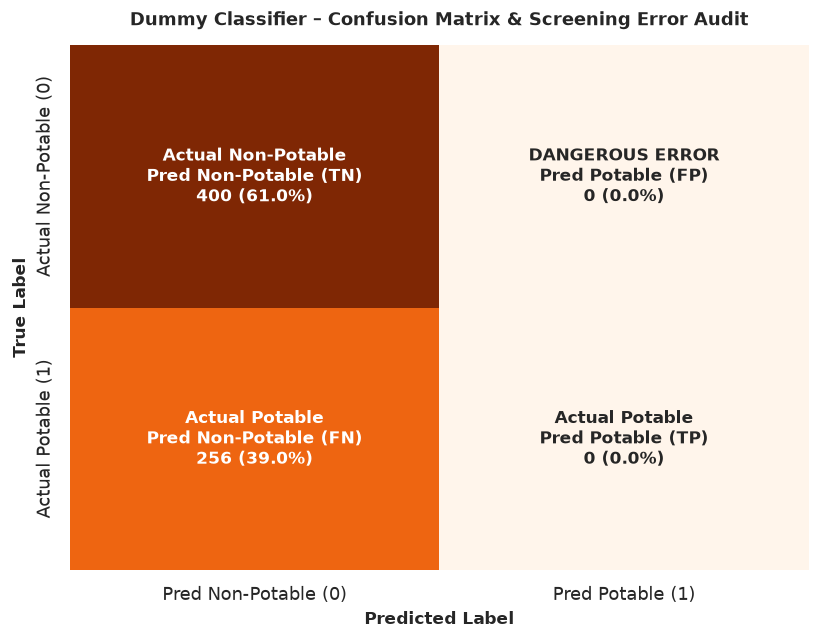

✓ Saved: ../results/figures/confusion_matrix_dummy_classifier.png


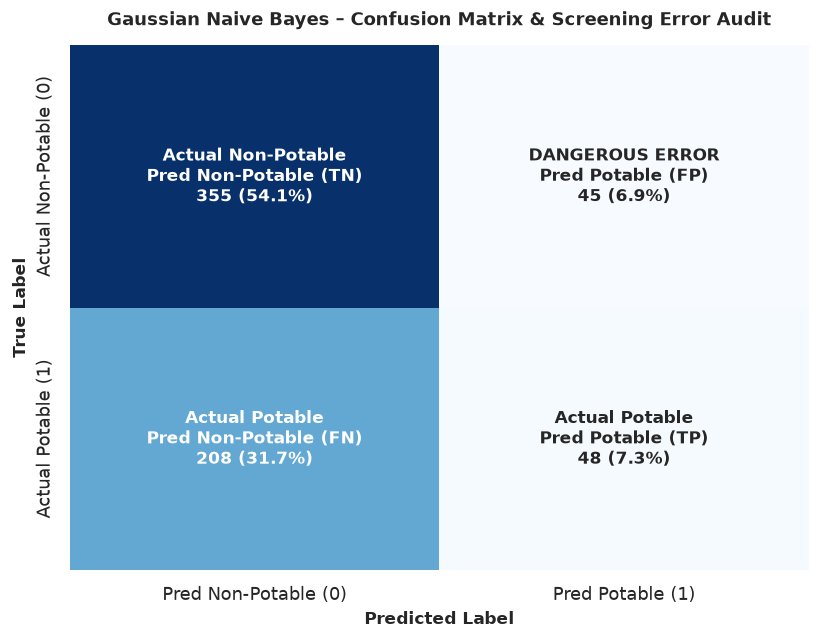

✓ Saved: ../results/figures/confusion_matrix_gaussian_nb.png


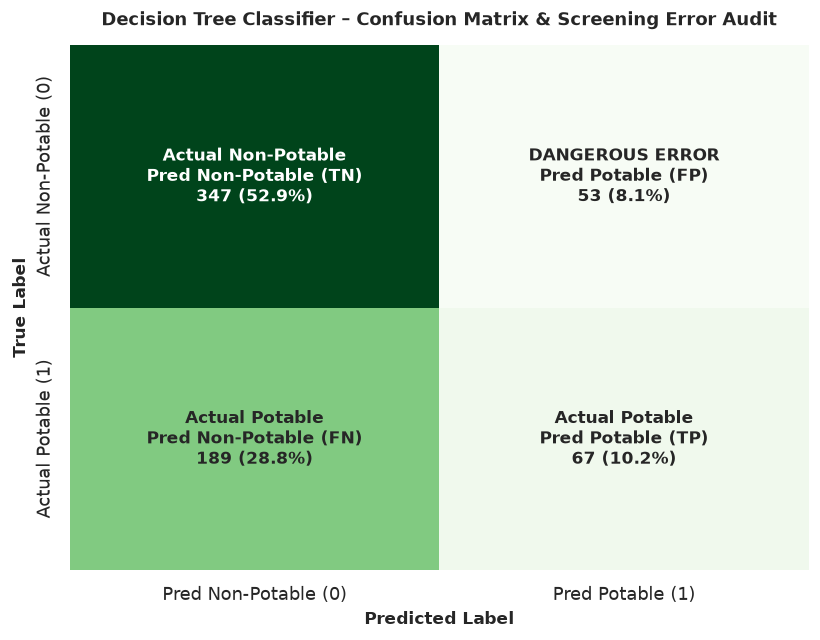

✓ Saved: ../results/figures/confusion_matrix_decision_tree.png


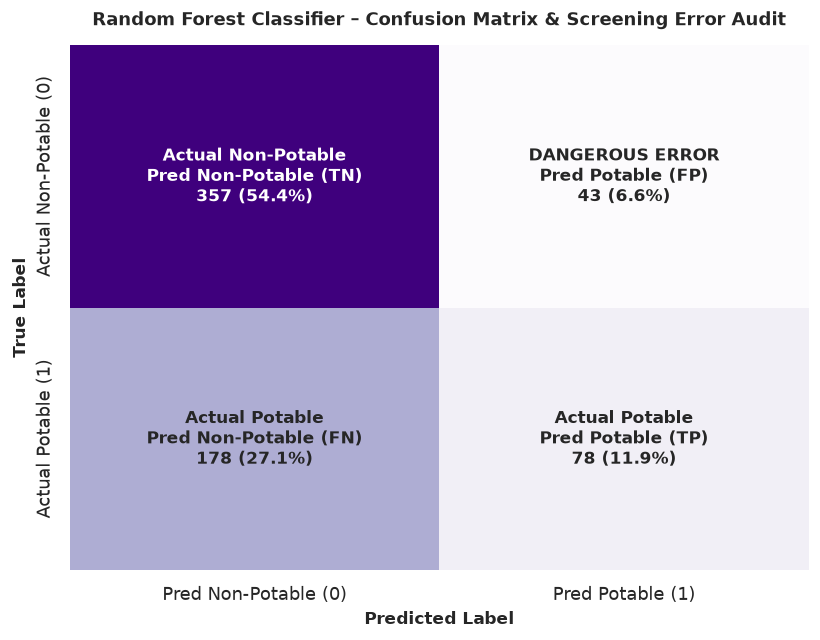

✓ Saved: ../results/figures/confusion_matrix_random_forest.png


In [10]:
os.makedirs('../results/figures', exist_ok=True)

models_for_cm = [
    ('Dummy Classifier',
     y_pred_dummy,
     'confusion_matrix_dummy_classifier.png',
     'Oranges'),

    ('Gaussian Naive Bayes',
     y_pred_gnb,
     'confusion_matrix_gaussian_nb.png',
     'Blues'),

    ('Decision Tree Classifier',
     y_pred_dt,
     'confusion_matrix_decision_tree.png',
     'Greens'),

    ('Random Forest Classifier',
     y_pred_rf,
     'confusion_matrix_random_forest.png',
     'Purples')
]

for name, preds, filename, cmap in models_for_cm:
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    total = cm.sum()
    
    annot = np.array([
        [f"Actual Non-Potable\nPred Non-Potable (TN)\n{tn} ({tn/total:.1%})",
         f"DANGEROUS ERROR\nPred Potable (FP)\n{fp} ({fp/total:.1%})"],
        [f"Actual Potable\nPred Non-Potable (FN)\n{fn} ({fn/total:.1%})",
         f"Actual Potable\nPred Potable (TP)\n{tp} ({tp/total:.1%})"]
    ])
    
    fig, ax = plt.subplots(figsize=(7, 5.5))
    sns.heatmap(cm, annot=annot, fmt='', cmap=cmap, cbar=False,
                xticklabels=['Pred Non-Potable (0)', 'Pred Potable (1)'],
                yticklabels=['Actual Non-Potable (0)', 'Actual Potable (1)'],
                annot_kws={'fontsize': 10, 'fontweight': 'bold'}, ax=ax)
    
    ax.set_title(f'{name} – Confusion Matrix & Screening Error Audit', fontsize=11, fontweight='bold', pad=12)
    ax.set_xlabel('Predicted Label', fontsize=10, fontweight='bold')
    ax.set_ylabel('True Label', fontsize=10, fontweight='bold')
    
    plt.tight_layout()
    save_path = os.path.join('../results/figures', filename)
    plt.savefig(save_path, dpi=300)
    plt.show()
    print(f"✓ Saved: {save_path}")

## Comparative Receiver Operating Characteristic (ROC) Curves

Gaussian Naive Bayes (AUC = **0.609**) and Decision Tree (AUC = **0.601**) demonstrate modest discrimination above random ranking performance (AUC = 0.500).Random Forest (AUC = **0.641**) is also evaluated using the same test dataset to compare its ability to distinguish between potable and non-potable water.

The ROC-AUC scores indicate how effectively each model separates the two classes. However, these results represent preliminary dataset-based screening performance and do not establish real-world drinking-water safety.

These predictions cannot certify water potability. Real-world assessment requires comprehensive laboratory testing by qualified professionals.

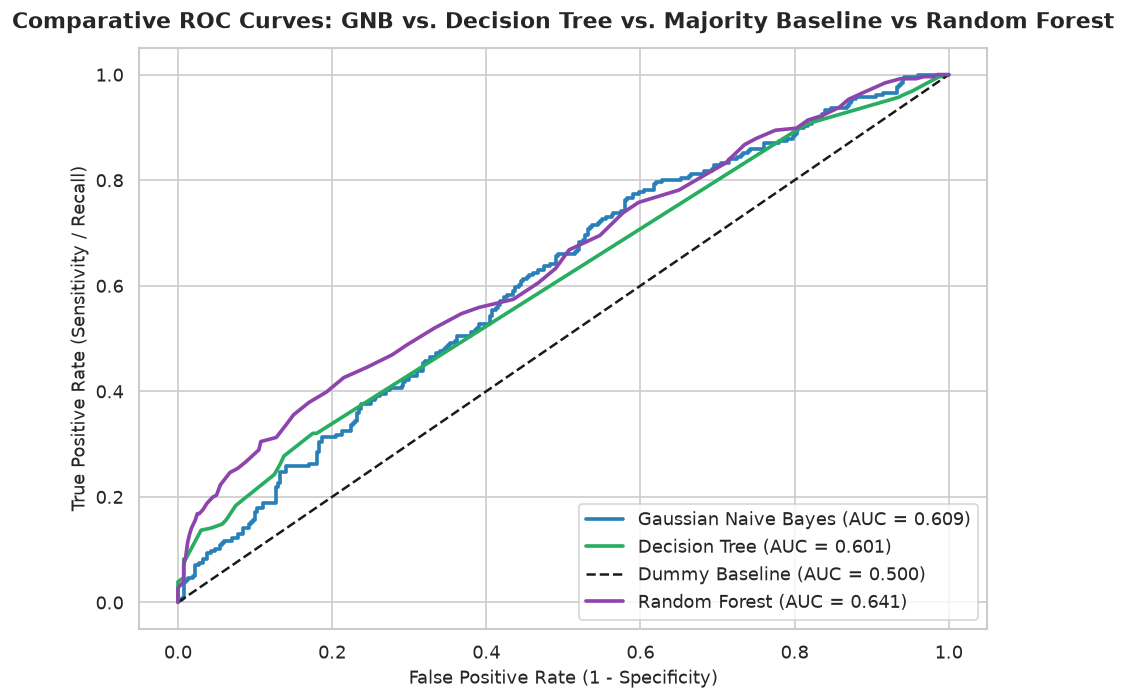

✓ Saved comparative ROC curve to: ../results/figures/comparative_roc_curves.png


In [11]:
fpr_gnb, tpr_gnb, _ = roc_curve(y_test, y_prob_gnb)
auc_gnb = roc_auc_score(y_test, y_prob_gnb)

fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
auc_dt = roc_auc_score(y_test, y_prob_dt)

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_rf = roc_auc_score(y_test, y_prob_rf)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr_gnb, tpr_gnb, label=f'Gaussian Naive Bayes (AUC = {auc_gnb:.3f})', color='#2980b9', lw=2.2)
ax.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {auc_dt:.3f})', color='#27ae60', lw=2.2)
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Dummy Baseline (AUC = 0.500)')
ax.plot(
    fpr_rf,
    tpr_rf,
    label=f'Random Forest (AUC = {auc_rf:.3f})',
    color='#8e44ad',
    lw=2.2
)

ax.set_title('Comparative ROC Curves: GNB vs. Decision Tree vs. Majority Baseline vs Random Forest', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax.set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11)
ax.legend(loc='lower right', fontsize=11)
plt.tight_layout()
roc_path = '../results/figures/comparative_roc_curves.png'
plt.savefig(roc_path, dpi=300)
plt.show()
print(f"✓ Saved comparative ROC curve to: {roc_path}")

# Phase 8: Preserved Model Saving with Joblib (Handover to Member 3)

Persisting the fitted Scikit-learn pipelines as standalone `.joblib` objects in `models/`.

- **`models/gaussian_nb_pipeline.joblib`:** Preprocessing (median imputer + StandardScaler) + GaussianNB.
- **`models/decision_tree_pipeline.joblib`:** Preprocessing (median imputer) + DecisionTreeClassifier.
- **`models/random_forest_pipeline.joblib`:** Preprocessing (median imputer) + RandomForestClassifier with 100 decision trees.
- **Preserved Filenames & Signatures:** Member 3 can load all three saved pipelines using `joblib.load()` and directly run `model.predict(input_df)` on raw input values without manually repeating preprocessing.
- **Frontend Integration:** All three models must receive the same nine water-quality parameters with the correct feature names, order and units to ensure consistent predictions.
- **Model Verification:** The saved pipelines are reloaded and tested to confirm they produce the same predictions as the original trained models.

In [16]:
os.makedirs('../models', exist_ok=True)

# 1. Export Gaussian Naive Bayes Pipeline
gnb_export_path = '../models/gaussian_nb_pipeline.joblib'
joblib.dump(gnb_pipeline, gnb_export_path)
print(f"✓ Saved GaussianNB Pipeline to: {gnb_export_path}")

# 2. Export Decision Tree Pipeline
dt_export_path = '../models/decision_tree_pipeline.joblib'
joblib.dump(dt_pipeline, dt_export_path)
print(f"✓ Saved Decision Tree Pipeline to: {dt_export_path}")

# 3. Save Random Forest Model
rf_export_path = '../models/random_forest_pipeline.joblib'
joblib.dump(rf_pipeline, rf_export_path)
print(f"✓ Random Forest model saved to: {rf_export_path}")

# 4. Verification test: Load models and verify prediction on sample data
loaded_gnb = joblib.load(gnb_export_path)
loaded_dt = joblib.load(dt_export_path)
loaded_rf = joblib.load(rf_export_path)


sample_input = X_test.iloc[:3]

print("\n--- Verification Test on Loaded Pipelines ---")
print("Input Features Sample:")
display(sample_input)

print(f"Loaded GNB Predictions: {loaded_gnb.predict(sample_input).tolist()}")
print(f"Loaded DT Predictions:  {loaded_dt.predict(sample_input).tolist()}")
print(f"Loaded RF Predictions:  {loaded_rf.predict(sample_input).tolist()}")

assert (
    loaded_rf.predict(sample_input)
    == rf_pipeline.predict(sample_input)
).all()

print("\n✓ All three model pipelines verified and ready for Streamlit App integration!")
# Compare actual labels with predictions
print("\n--- Actual vs Predicted Labels ---")
print("Actual Labels:", y_test.iloc[:3].tolist())
print("Naive Bayes:  ", loaded_gnb.predict(sample_input).tolist())
print("Decision Tree:", loaded_dt.predict(sample_input).tolist())
print("Random Forest:", loaded_rf.predict(sample_input).tolist())


✓ Saved GaussianNB Pipeline to: ../models/gaussian_nb_pipeline.joblib
✓ Saved Decision Tree Pipeline to: ../models/decision_tree_pipeline.joblib
✓ Random Forest model saved to: ../models/random_forest_pipeline.joblib

--- Verification Test on Loaded Pipelines ---
Input Features Sample:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
664,NaN,188.743562,19037.462638,6.034236,NaN,388.065857,15.149068,78.499418,2.723651
2530,6.172517,187.787017,10498.635154,7.722561,322.521035,467.090425,21.233978,68.163642,4.129985
2870,NaN,176.386651,26003.163265,7.809251,358.429774,336.142005,14.447961,90.224844,4.410674


Loaded GNB Predictions: [0, 0, 0]
Loaded DT Predictions:  [0, 0, 0]
Loaded RF Predictions:  [0, 0, 0]

✓ All three model pipelines verified and ready for Streamlit App integration!

--- Actual vs Predicted Labels ---
Actual Labels: [1, 0, 0]
Naive Bayes:   [0, 0, 0]
Decision Tree: [0, 0, 0]
Random Forest: [0, 0, 0]
